# C07a — Binoculars NF4: OG versus NS10

This is a **4-bit quantized variant**, with BF16 compute, of the published Falcon pair. Run in a fresh kernel inside the reproduction project. One model occupies the GPU at a time; no model weights are deliberately offloaded into CPU RAM. Model loading still needs temporary host memory, so 6 GB RAM remains tight and successful loading is not guaranteed.

Install the dependencies in the next cell if necessary, then restart the kernel. Existing Hugging Face model downloads are reused when their revisions match. Both scoring passes must run anew: BF16 logits and scores are incompatible with NF4. A separate output directory protects the old run. Every completed document is saved for resumption.

All 54 OG/NS10 pairs use the same RAID human references. Primary results are AUROC and RAID-validation-calibrated TPR. Published BF16 thresholds are shown only as **uncalibrated diagnostics** for this variant. Scores observe the first 512 Falcon tokens. Lower raw ratio means more AI-like; the plotted AI score is its negative, not a probability.

References: [Binoculars paper](https://arxiv.org/abs/2401.12070), [pinned implementation](https://github.com/ahans30/Binoculars/tree/c8ae2f90d50ee696418bc71d8d9e5020e5f9d7b8), [Transformers NF4 documentation](https://huggingface.co/docs/transformers/v4.44.2/quantization/bitsandbytes).


In [1]:
# Run once if needed, then restart the kernel. Keep your existing CUDA PyTorch.
# %pip install "transformers==4.44.2" "accelerate==0.34.2" "bitsandbytes>=0.43.3" huggingface_hub safetensors pandas pyarrow matplotlib scikit-learn tqdm psutil


In [2]:
# %pip install "transformers==4.44.2" "accelerate==0.34.2" "bitsandbytes>=0.43.3" huggingface_hub safetensors pandas pyarrow matplotlib scikit-learn tqdm psutil

In [3]:
from pathlib import Path
import os,json,hashlib,tempfile,time,getpass,math
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve,auc
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
 if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT = ROOT / "results/causal/C07a_Binoculars_NF4_OG_NS10_pinned_v1"
OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'responses';CACHE.mkdir(exist_ok=True)
SEED=20260922
MAX_TOKENS=512
DELETE_CONSUMED_LOGITS=True
OBSERVER='tiiuae/falcon-7b'
PERFORMER='tiiuae/falcon-7b-instruct'
LOGITS=OUT/'observer_logits';LOGITS.mkdir(exist_ok=True)
import gc,shutil,importlib.metadata
import torch
from transformers import AutoTokenizer,AutoModelForCausalLM,AutoConfig,BitsAndBytesConfig
from huggingface_hub import HfApi
assert torch.cuda.is_available(), 'This configuration needs a CUDA GPU.'
assert torch.cuda.is_bf16_supported(), 'BF16 required; do not silently change detector precision.'

def text_sha(t):return hashlib.sha256(str(t).encode()).hexdigest()
def file_sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic(path,data):
 fd,tmp=tempfile.mkstemp(dir=Path(path).parent,suffix='.tmp')
 try:
  with os.fdopen(fd,'wb') as f:f.write(data);f.flush();os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def save_json(obj,p):atomic(p,json.dumps(obj,sort_keys=True,indent=2,allow_nan=False).encode())
def save_csv(df,p):atomic(p,df.to_csv(index=False).encode())
def freeze(obj,p):
 if p.exists():assert json.loads(p.read_text())==obj,'Protocol changed; use a new OUT directory.'
 else:save_json(obj,p)

import bitsandbytes,psutil
print(f"Available RAM: {psutil.virtual_memory().available/2**30:.2f} GiB")
print(f"Free GPU memory: {torch.cuda.mem_get_info()[0]/2**30:.2f} GiB")


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available RAM: 21.87 GiB
Free GPU memory: 6.68 GiB


In [4]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)


raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all()
h=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
h['case_id']='';h['stage']='Human'
o=og.assign(stage='OG',split='test',label=1)
n=ns[['case_id','source_id','domain','text']].assign(stage='NS10',split='test',label=1)
docs=pd.concat([h,o,n],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha)
docs['words']=docs.text.str.split().str.len()
unique=docs[['text_sha','text','words']].drop_duplicates('text_sha').reset_index(drop=True)
display(docs.groupby(['stage','split']).size().rename('documents'))

# Release larger source tables before model loading; docs/unique retain evaluation texts.
del meta,corpus,raid,rm,h,o,n,keys,expected
gc.collect()


stage  split     
Human  test          138
       validation    135
NS10   test           54
OG     test           54
Name: documents, dtype: int64

20

In [5]:
# Freeze model revisions and score/cache contract before downloading weights.
revpath=OUT/'model_revisions.json'
if revpath.exists():revisions=json.loads(revpath.read_text())
else:
 prior=ROOT/'results/causal/C07a_Binoculars_OG_NS10_v1/model_revisions.json'
 revisions=json.loads(prior.read_text()) if prior.exists() else {name:HfApi().model_info(name).sha for name in [OBSERVER,PERFORMER]}
 save_json(revisions,revpath)
tok=AutoTokenizer.from_pretrained(OBSERVER,revision=revisions[OBSERVER])
other=AutoTokenizer.from_pretrained(PERFORMER,revision=revisions[PERFORMER])
assert tok.vocab==other.vocab,'The model tokenizers must share their vocabulary.'
if tok.pad_token is None:tok.pad_token=tok.eos_token
del other
contract=dict(version='C07a_Binoculars_NF4_v1',quantization='NF4_double_quant',metric_device='cpu',models=revisions,max_tokens=MAX_TOKENS,
 dtype='bfloat16',attention='eager',metric='official_mean_nll_over_cross_entropy',
 code_commit='c8ae2f90d50ee696418bc71d8d9e5020e5f9d7b8',
 runtime={p:importlib.metadata.version(p) for p in ['torch','transformers','accelerate','bitsandbytes']},
 inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
 BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json');signature=text_sha(json.dumps(contract,sort_keys=True))
def cache_path(sha):return CACHE/(text_sha(signature+sha)+'.json')
def logit_path(sha):return LOGITS/(text_sha(signature+sha)+'.pt')
def encode(text):return tok(text,return_tensors='pt',truncation=True,max_length=MAX_TOKENS)
def complete(sha):
 p=cache_path(sha)
 if not p.exists():return False
 r=json.loads(p.read_text())
 assert r['contract']==signature and r['text_sha']==sha and np.isfinite(r['Binoculars_score'])
 return True
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in unique.itertuples()}
assert min(lengths.values())>=2,'A document has fewer than two tokens; inspect rather than silently excluding it.'
docs['total_tokens']=docs.text_sha.map(lengths)
docs['scored_tokens']=docs.total_tokens.clip(upper=MAX_TOKENS)
docs['truncated']=docs.total_tokens.gt(MAX_TOKENS)
save_csv(docs.drop(columns='text'),OUT/'score_manifest.csv')
display(docs.groupby('stage').agg(documents=('text_sha','size'),truncated=('truncated','sum')))
vocab=AutoConfig.from_pretrained(OBSERVER,revision=revisions[OBSERVER]).vocab_size
missing=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in missing if not logit_path(r['text_sha']).exists())
print(f'Pending scores: {len(missing)}; additional observer cache: {needed/2**30:.2f} GiB')
print(f'Free output-disk space: {shutil.disk_usage(OUT).free/2**30:.1f} GiB; model downloads need about 28 GB separately.')
assert shutil.disk_usage(OUT).free>needed+2*2**30,'Insufficient space for observer cache.'


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,documents,truncated
stage,,
Human,273,11
NS10,54,25
OG,54,1


Pending scores: 381; additional observer cache: 31.60 GiB
Free output-disk space: 80.9 GiB; model downloads need about 28 GB separately.


In [6]:
# Default metric functions from the pinned official implementation (see reference above).
import numpy as np
import torch
import transformers

ce_loss_fn = torch.nn.CrossEntropyLoss(reduction="none")
softmax_fn = torch.nn.Softmax(dim=-1)


def perplexity(encoding: transformers.BatchEncoding,
               logits: torch.Tensor,
               median: bool = False,
               temperature: float = 1.0):
    shifted_logits = logits[..., :-1, :].contiguous() / temperature
    shifted_labels = encoding.input_ids[..., 1:].contiguous()
    shifted_attention_mask = encoding.attention_mask[..., 1:].contiguous()

    if median:
        ce_nan = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels).
                  masked_fill(~shifted_attention_mask.bool(), float("nan")))
        ppl = np.nanmedian(ce_nan.cpu().float().numpy(), 1)

    else:
        ppl = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels) *
               shifted_attention_mask).sum(1) / shifted_attention_mask.sum(1)
        ppl = ppl.to("cpu").float().numpy()

    return ppl


def entropy(p_logits: torch.Tensor,
            q_logits: torch.Tensor,
            encoding: transformers.BatchEncoding,
            pad_token_id: int,
            median: bool = False,
            sample_p: bool = False,
            temperature: float = 1.0):
    vocab_size = p_logits.shape[-1]
    total_tokens_available = q_logits.shape[-2]
    p_scores, q_scores = p_logits / temperature, q_logits / temperature

    p_proba = softmax_fn(p_scores).view(-1, vocab_size)

    if sample_p:
        p_proba = torch.multinomial(p_proba.view(-1, vocab_size), replacement=True, num_samples=1).view(-1)

    q_scores = q_scores.view(-1, vocab_size)

    ce = ce_loss_fn(input=q_scores, target=p_proba).view(-1, total_tokens_available)
    padding_mask = (encoding.input_ids != pad_token_id).type(torch.uint8)

    if median:
        ce_nan = ce.masked_fill(~padding_mask.bool(), float("nan"))
        agg_ce = np.nanmedian(ce_nan.cpu().float().numpy(), 1)
    else:
        agg_ce = (((ce * padding_mask).sum(1) / padding_mask.sum(1)).to("cpu").float().numpy())

    return agg_ce


In [7]:
def save_tensor(obj,path):
 fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp');os.close(fd)
 try:
  torch.save(obj,tmp)
  with open(tmp,'rb') as f:os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def load_model(name):
 print('Loading',name,flush=True)
 quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
  bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.bfloat16)
 model=AutoModelForCausalLM.from_pretrained(name,revision=revisions[name],
  torch_dtype=torch.bfloat16,quantization_config=quant,device_map={'':0},
  low_cpu_mem_usage=True,attn_implementation='eager')
 print(f'Model footprint: {model.get_memory_footprint()/2**30:.2f} GiB',flush=True)
 model.eval();return model
@torch.inference_mode()
def forward(model,encoding):
 # Accelerate dispatch hooks move inputs to the execution device as necessary.
 device=model.get_input_embeddings().weight.device
 if device.type=='meta':device=torch.device('cuda:0')
 return model(**{k:v.to(device) for k,v in encoding.items()},use_cache=False).logits.detach().cpu()

# Pass 1: resumable observer logits. No performer is resident.
pending=[r for r in unique.to_dict('records') if not complete(r['text_sha']) and not logit_path(r['text_sha']).exists()]
model=None
try:
 if pending:model=load_model(OBSERVER)
 for i,r in enumerate(tqdm(pending,desc='Observer pass')):
  enc=encode(r['text']);p=forward(model,enc)
  save_tensor(dict(contract=signature,text_sha=r['text_sha'],ids=enc.input_ids,logits=p),logit_path(r['text_sha']))
  del p
  print(f"Observer saved {i+1}/{len(pending)}",flush=True)
finally:
 del model;gc.collect();torch.cuda.empty_cache()


Loading tiiuae/falcon-7b


Loading checkpoint shards: 100%|████████████████████████████████████████████████████████████████████| 2/2 [00:04<00:00,  2.25s/it]

Model footprint: 3.65 GiB



Observer pass:   0%|                                                                                      | 0/381 [00:00<?, ?it/s]

Observer saved 1/381


...

Observer pass:  99%|███████████████████████████████████████████████████████████████████████████▌| 379/381 [02:57<00:01,  1.73it/s]

Observer saved 380/381


Observer pass: 100%|███████████████████████████████████████████████████████████████████████████▊| 380/381 [02:58<00:00,  1.73it/s]

Observer saved 381/381


Observer pass: 100%|████████████████████████████████████████████████████████████████████████████| 381/381 [02:58<00:00,  2.13it/s]


In [8]:
# Pass 2: final ratios, checkpointed after every document.
pending=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
model=None
try:
 if pending:model=load_model(PERFORMER)
 for i,r in enumerate(tqdm(pending,desc='Performer pass')):
  started=time.perf_counter();enc=encode(r['text'])
  saved=torch.load(logit_path(r['text_sha']),map_location='cpu',weights_only=True)
  assert saved['contract']==signature and saved['text_sha']==r['text_sha']
  assert torch.equal(saved['ids'],enc.input_ids)
  # Score the saved logits on CPU to reserve GPU space for the model.
  q=forward(model,enc);p=saved['logits']
  with torch.inference_mode():
   numerator=float(perplexity(enc,q)[0])
   denominator=float(entropy(p,q,enc,tok.pad_token_id)[0])
  assert np.isfinite(numerator) and np.isfinite(denominator) and denominator>0
  ratio=numerator/denominator
  record=dict(contract=signature,text_sha=r['text_sha'],Binoculars_score=ratio,AI_score=-ratio,
   mean_nll=numerator,cross_entropy=denominator,scored_tokens=int(enc.input_ids.shape[1]),
   total_tokens=lengths[r['text_sha']],seconds=time.perf_counter()-started)
  save_json(record,cache_path(r['text_sha']))
  if DELETE_CONSUMED_LOGITS:logit_path(r['text_sha']).unlink(missing_ok=True)
  del p,q,enc,saved
  print(f"Final score saved {i+1}/{len(pending)}: {ratio:.6f}",flush=True)
finally:
 del model;gc.collect();torch.cuda.empty_cache()
records=[]
for r in docs.drop(columns='text').to_dict('records'):
 assert complete(r['text_sha'])
 records.append({**r,**json.loads(cache_path(r['text_sha']).read_text())})
scored=pd.DataFrame(records);save_csv(scored,OUT/'all_scores.csv')
O=scored.loc[scored.stage.eq('OG')];N=scored.loc[scored.stage.eq('NS10')];R=scored.loc[scored.stage.eq('Human')]
paired=O[['case_id','source_id','domain','AI_score']].rename(columns={'AI_score':'OG_AI_score'}).merge(
 N[['case_id','source_id','AI_score']].rename(columns={'AI_score':'NS10_AI_score'}),
 on=['case_id','source_id'],validate='one_to_one')
assert len(paired)==54
save_csv(paired,OUT/'paired_scores.csv')
print('All 54 OG/NS10 pairs scored. AI_score is minus the ratio, not a probability.')


Loading tiiuae/falcon-7b-instruct


Loading checkpoint shards: 100%|████████████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.41s/it]


Model footprint: 3.65 GiB


Performer pass:   0%|                                                                                     | 0/381 [00:00<?, ?it/s]

Final score saved 1/381: 0.950758


...

Final score saved 380/381: 0.955801


Performer pass: 100%|██████████████████████████████████████████████████████████████████████████▊| 380/381 [03:53<00:00,  1.30it/s]

Final score saved 381/381: 1.015228


Performer pass: 100%|███████████████████████████████████████████████████████████████████████████| 381/381 [03:54<00:00,  1.63it/s]


All 54 OG/NS10 pairs scored. AI_score is minus the ratio, not a probability.


In [9]:
mix=paired.domain.value_counts(normalize=True)
def humans(split):
    q=R.loc[R.split.eq(split)&R.label.eq(0)&R.domain.isin(mix.index)].copy()
    counts=q.domain.value_counts();assert set(mix.index)<=set(counts.index)
    q['weight']=[mix[d]/counts[d] for d in q.domain]
    assert np.isclose(q.weight.sum(),1)
    save_csv(q,OUT/(split+'_human_reference.csv'));return q
cal=humans('validation');human=humans('test')
cuts=np.r_[np.inf,np.unique(cal.AI_score)[::-1],-np.inf]
st=pd.DataFrame(dict(threshold=cuts,
    calibration_FPR=[cal.loc[cal.AI_score>c,'weight'].sum() for c in cuts],
    test_FPR=[human.loc[human.AI_score>c,'weight'].sum() for c in cuts]))
rows=[]
for name in ['OG','NS10']:
    ai=paired[name+'_AI_score'].to_numpy();hs=human.AI_score.to_numpy()
    fpr,tpr,_=roc_curve(np.r_[np.zeros(len(hs)),np.ones(len(ai))],np.r_[hs,ai],
        sample_weight=np.r_[human.weight,np.ones(len(ai))/len(ai)],drop_intermediate=False)
    rows.append(dict(stage=name,cases=len(ai),AUROC=auc(fpr,tpr),mean_AI_score=ai.mean(),median_AI_score=np.median(ai)))
    st[name]=[(ai>c).mean() for c in cuts]
summary=pd.DataFrame(rows);display(summary.round(6))
save_csv(summary,OUT/'stage_summary.csv');save_csv(st,OUT/'C07a_TPR_staircase.csv')
# Conservative validation-human thresholds; report realized test FPR explicitly.
operating=[]
for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1.]:
    eligible=st.loc[st.calibration_FPR<=target+1e-12]
    row=eligible.iloc[-1].to_dict();row['target_FPR']=target;operating.append(row)
operating=pd.DataFrame(operating)
save_csv(operating,OUT/'operating_points.csv');display(operating)

# Paired AUROC change against the fixed, genre-weighted human reference.
# Each AI observation contributes its probability of outranking a human (ties half).
hs=human.AI_score.to_numpy();hw=human.weight.to_numpy()
def auc_contributions(scores):
    a=np.asarray(scores)[:,None];return (((a>hs)+.5*(a==hs))*hw).sum(axis=1)
d=auc_contributions(paired.NS10_AI_score)-auc_contributions(paired.OG_AI_score)
rng=np.random.default_rng(SEED);ix=rng.integers(0,len(paired),size=(10000,len(paired)))
changes=[]
for metric,v in [('AUROC',d),('AI_score',(paired.NS10_AI_score-paired.OG_AI_score).to_numpy())]:
    lo,hi=np.quantile(v[ix].mean(axis=1),[.025,.975])
    changes.append(dict(metric=metric,comparison='NS10_minus_OG',cases=len(paired),mean_delta=v.mean(),
                        ci_low=lo,ci_high=hi,increased=int((v>0).sum()),decreased=int((v<0).sum())))
changes=pd.DataFrame(changes);save_csv(changes,OUT/'paired_changes.csv');display(changes)
print('Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.')


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.905163,-0.765013,-0.715873
1,NS10,54,0.721606,-0.919246,-0.907727


,threshold,calibration_FPR,test_FPR,OG,NS10,target_FPR
0,-0.864865,0.000000,0.016708,0.740741,0.370370,0.000
1,-0.864865,0.000000,0.016708,0.740741,0.370370,0.001
2,-0.864865,0.000000,0.016708,0.740741,0.370370,0.005
3,-0.865854,0.008889,0.016708,0.740741,0.370370,0.010
4,-0.890110,0.017778,0.025480,0.796296,0.444444,0.020
5,-0.906015,0.042175,0.048670,0.814815,0.481481,0.050
6,-0.915584,0.094455,0.088530,0.814815,0.537037,0.100
7,-0.939024,0.198640,0.205599,0.870370,0.537037,0.200
8,-0.976959,0.499628,0.419790,0.944444,0.740741,0.500
9,-inf,1.000000,1.000000,1.000000,1.000000,1.000


,metric,comparison,cases,mean_delta,ci_low,ci_high,increased,decreased
0,AUROC,NS10_minus_OG,54,-0.183557,-0.283240,-0.084525,9,40
1,AI_score,NS10_minus_OG,54,-0.154232,-0.194652,-0.110421,10,44


Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.


In [10]:
# BF16 thresholds are UNCALIBRATED diagnostics for NF4, not primary operating points.
published=[]
for mode,raw_cut in [('accuracy',0.9015310749276843),('low_FPR',0.8536432310785527)]:
 published.append(dict(mode=mode,raw_threshold=raw_cut,
  validation_FPR=cal.loc[cal.AI_score > -raw_cut,'weight'].sum(),
  test_FPR=human.loc[human.AI_score > -raw_cut,'weight'].sum(),
  OG_TPR=float((paired.OG_AI_score > -raw_cut).mean()),
  NS10_TPR=float((paired.NS10_AI_score > -raw_cut).mean())))
published=pd.DataFrame(published);display(published)
save_csv(published,OUT/'published_thresholds.csv')


,mode,raw_threshold,validation_FPR,test_FPR,OG_TPR,NS10_TPR
0,accuracy,0.901531,0.042175,0.040734,0.796296,0.462963
1,low_FPR,0.853643,0.000000,0.007937,0.740741,0.370370


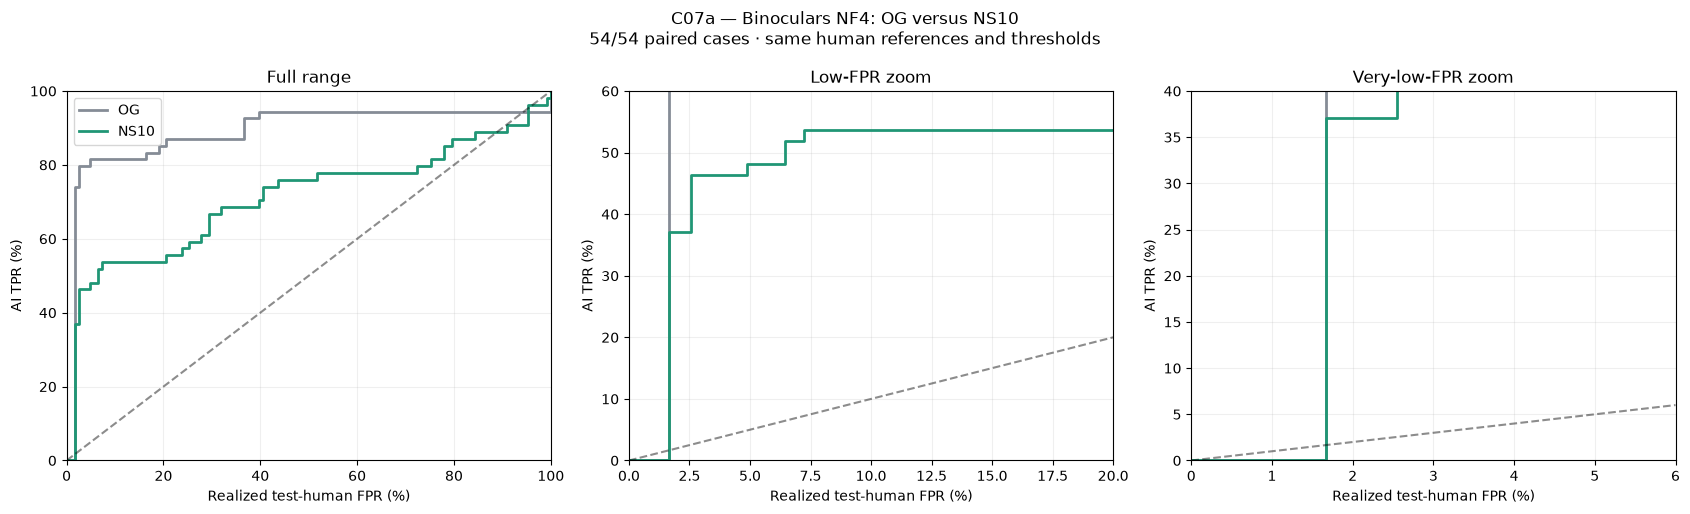

Saved all scores, thresholds, paired comparisons and figures: ../results/causal/C07a_Binoculars_NF4_OG_NS10_pinned_v1
Training-free detector; RAID validation humans calibrate thresholds only.


In [11]:
COLORS={'OG':'#858C96','NS10':'#209675'}
def save_figure(fig,stem):
    for folder in [OUT,ROOT/'figures']:
        folder.mkdir(exist_ok=True,parents=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xl,yl,title) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
    for name in COLORS:ax.step(st.test_FPR*100,st[name]*100,where='post',color=COLORS[name],lw=2,label=name)
    hi=min(xl[1],yl[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.45)
    ax.set(xlim=xl,ylim=yl,title=title,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
axs[0].legend()
fig.suptitle(f'C07a — Binoculars NF4: OG versus NS10\n{len(paired)}/54 paired cases · same human references and thresholds')
fig.tight_layout();save_figure(fig,'C07a_Binoculars_NF4_OG_NS10_TPR_staircase')


print('Saved all scores, thresholds, paired comparisons and figures:',OUT)
print('Training-free detector; RAID validation humans calibrate thresholds only.')


## Interpretation

Compare OG and NS10 AUROC and TPR at identical thresholds. Report realized test-human FPR, prefix truncation, and both published and RAID-calibrated thresholds. Negative paired AI-score/AUROC changes indicate reduced detectability. The staircase uses validation-derived thresholds; AUROC uses all test score thresholds, so the staircase is not an exact rendering of the AUROC integral.

This is a new detector evaluation of already fixed attacks, not evidence that every detector will fail. Bootstrap intervals hold the human reference fixed. Binoculars has no supervised training stage to repeat as a 20/34 fine-tuning experiment; any learned adaptation would need a separately specified method.

Caches are bound to text hashes, model revisions, runtime versions and the frozen input files. Changing the protocol requires a new output directory. After interruption, restart the kernel and rerun: completed final scores and observer logits are reused. Heavy model inference was not executed when preparing this notebook.

Report this as **Binoculars NF4**, not an exact BF16 replication. Host-side metric computation and quantization are recorded in the cache contract. No full Falcon inference was tested when preparing this notebook; hardware fit must be established on the first document. Downloaded checkpoints may be large despite 4-bit inference because weights are quantized at load time.
